# 7. Final Training and Definitive Evaluation of the 1D CNN

This notebook performs the final training and one-time evaluation of the 1D CNN using normalized ECG signals.

The definitive configuration is loaded automatically from the JSON artifact created at the end of notebook 6. This keeps the final experiment consistent with the configuration selected after comparing the initial architecture, the Optuna configuration, and the corresponding experiments with non-normalized signals.

The workflow is:

1. load the definitive configuration and prepared normalized signals;
2. verify the saved development/test split and patient separation;
3. prepare the complete development and untouched test datasets;
4. train the selected architecture on all development signals for exactly four epochs;
5. evaluate the resulting model once on the untouched test set;
6. save the model, metrics, predictions, patient summaries, and interpretability analyses.

The final epoch count is fixed at four based on the previous training comparison. The test set is never used to select hyperparameters or the decision threshold. The final threshold is loaded from the same artifact as the model configuration.


# 7.1. Imports, Reproducibility, and Experiment Scope

This section imports the libraries used throughout the final experiment and defines the reproducibility helper. The random seed is loaded from notebook 6 and applied to Python, NumPy, PyTorch, and CUDA when available.


In [5]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
)


def set_reproducible_seed(seed):
    """Set Python, NumPy, PyTorch, and CUDA seeds."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# 7.2. Load the Definitive Configuration

The JSON file was generated by notebook 6 after model selection. It contains the selected architecture, optimization parameters, early-stopping settings, decision threshold, and provenance information.

Loading this file avoids manually copying hyperparameters between notebooks. The configuration is validated before any data or model is created.


In [6]:
final_config_path = (
    Path("data")
    / "entrenamiento-final"
    / "final_normalized_signals_config.json"
)

if not final_config_path.is_file():
    raise FileNotFoundError(
        "The final configuration file was not found. "
        "Run the export cell at the end of notebook 6 first."
    )

with open(final_config_path, "r") as file:
    final_artifact = json.load(file)

if final_artifact.get("data_variant") != "normalized_signals":
    raise ValueError(
        "The configuration does not correspond to normalized signals."
    )

loaded_config = final_artifact["config"]
channels = tuple(int(channel) for channel in loaded_config["channels"])
dropout = float(loaded_config["dropout"])
learning_rate = float(loaded_config["learning_rate"])
batch_size = int(loaded_config["batch_size"])
kernel_size = int(loaded_config["kernel_size"])
weight_decay = float(loaded_config.get("weight_decay", 0.0))
random_seed = int(loaded_config.get("random_seed", 43))
max_epochs = int(loaded_config.get("max_epochs", 100))
patience = int(loaded_config.get("patience", 10))
min_delta = float(loaded_config.get("min_delta", 0.0))
use_scheduler = bool(loaded_config.get("use_scheduler", False))
final_threshold = float(final_artifact["selected_threshold"])

if use_scheduler:
    raise ValueError(
        "This final-training notebook expects a configuration without a scheduler."
    )

set_reproducible_seed(random_seed)

device = torch.device(
    loaded_config.get(
        "device",
        "cuda" if torch.cuda.is_available() else "cpu",
    )
)

print("Configuration loaded from:", final_config_path)
print("Data variant:", final_artifact["data_variant"])
print("Channels:", channels)
print("Dropout:", dropout)
print("Kernel size:", kernel_size)
print("Learning rate:", learning_rate)
print("Batch size:", batch_size)
print("Weight decay:", weight_decay)
print("Patience:", patience)
print("Final threshold:", final_threshold)
print("Device:", device)


Configuration loaded from: data/entrenamiento-final/final_normalized_signals_config.json
Data variant: normalized_signals
Channels: (64, 32, 64, 128)
Dropout: 0.21250046179095888
Kernel size: 5
Learning rate: 0.008678831241774139
Batch size: 16
Weight decay: 0.0
Patience: 10
Final threshold: 0.4
Device: cpu


# 7.3. Load Normalized Signals, Metadata, and Saved Splits

This section loads the normalized signals, patient and lead metadata, and the previously generated development/test split.

The saved split is reused without modification. Development is used for epoch selection and final training, while test remains isolated until the single final evaluation.


In [7]:
normalized_data_path = (
    Path("data")
    / "normalized_signals_clean.npz"
)


dataset_splits_path = (
    Path("data")
    / "splits"
    / "dataset_splits.npz"
)


for file_path in [
    normalized_data_path,
    dataset_splits_path,
]:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File does not exist: {file_path}"
        )


normalized_data = np.load(
    normalized_data_path
)

required_keys = {
    "signals",
    "label",
    "patient_id",
    "lead",
    "mat_path",
}

assert required_keys.issubset(
    set(normalized_data.files)
)


X = normalized_data[
    "signals"
].copy()

y_original = normalized_data[
    "label"
].astype(
    np.int64,
    copy=True,
)

Y = np.where(
    y_original == 1,
    1,
    0,
).astype(
    np.int64
)

patient_ids = normalized_data[
    "patient_id"
].astype(
    str,
    copy=True,
)

leads = normalized_data[
    "lead"
].astype(
    str,
    copy=True,
)

mat_paths = normalized_data[
    "mat_path"
].astype(
    str,
    copy=True,
)

normalized_data.close()


loaded_splits = np.load(
    dataset_splits_path
)

development_indices = loaded_splits[
    "development_indices"
].astype(
    np.int64,
    copy=True,
)

test_indices = loaded_splits[
    "test_indices"
].astype(
    np.int64,
    copy=True,
)


signals_tensor = torch.as_tensor(
    X,
    dtype=torch.float32,
).unsqueeze(1)

labels_tensor = torch.as_tensor(
    Y,
    dtype=torch.float32,
)


signals_dev_tensor = signals_tensor[
    development_indices
]

labels_dev_tensor = labels_tensor[
    development_indices
]

signals_test_tensor = signals_tensor[
    test_indices
]

labels_test_tensor = labels_tensor[
    test_indices
]


# Reconstruct a descriptive index from the loaded metadata.
dataset_index = pd.DataFrame(
    {
        "patient_id": patient_ids,
        "lead": leads,
        "label": Y,
        "mat_path": mat_paths,
    }
)


assert len(X) == len(Y)
assert len(X) == len(patient_ids)
assert len(X) == len(dataset_index)

assert signals_tensor.shape == (
    10577,
    1,
    252,
)

assert len(development_indices) == 9359
assert len(test_indices) == 1218

assert len(
    np.intersect1d(
        development_indices,
        test_indices,
    )
) == 0

development_patients = np.unique(
    patient_ids[development_indices]
)

test_patients = np.unique(
    patient_ids[test_indices]
)

assert len(
    np.intersect1d(
        development_patients,
        test_patients,
    )
) == 0

assert torch.isfinite(
    signals_tensor
).all()

print("Tensor completo:", signals_tensor.shape)
print("Development:", len(development_indices))
print("Test:", len(test_indices))
print("Shared patients between development and test: 0")

Tensor completo: torch.Size([10577, 1, 252])
Development: 9359
Test: 1218
Shared patients between development and test: 0


# 7.4. Prepare the Development Labels and Patient Metadata

No additional subtrain/final-validation split is created in this notebook. The complete development set is used for final training. The saved development/test split is preserved, and patient metadata is retained for later summaries and checks.

The number of training epochs is fixed at four from the previously completed comparison.


In [8]:
# Labels and patients belonging to development only.
y_dev = Y[
    development_indices
]

development_patient_ids = patient_ids[
    development_indices
]


# Basic checks for the complete development set.
assert len(y_dev) == len(development_indices)
assert len(development_patient_ids) == len(y_dev)


def describe_labels(name, labels):
    positives = int(
        np.sum(labels == 1)
    )

    negatives = int(
        np.sum(labels == 0)
    )

    percentage = (
        100
        * positives
        / len(labels)
    )

    print(
        f"{name}: "
        f"n={len(labels)}, "
        f"positive={positives}, "
        f"negative={negatives}, "
        f"positive%={percentage:.2f}%"
    )


describe_labels(
    "Development",
    y_dev,
)

print(
    "Development patients:",
    len(np.unique(development_patient_ids)),
)


Development: n=9359, positive=1740, negative=7619, positive%=18.59%
Development patients: 26


# 7.5. Build the Dataset and DataLoaders

This section defines the PyTorch Dataset and creates DataLoaders for the complete development set and the untouched test set.

Development batches are shuffled with a seeded generator. Test batches preserve a deterministic order so predictions remain aligned with metadata.


In [9]:
class ECGDataset(Dataset):
    """Dataset of ECG signals and binary labels for PyTorch."""

    def __init__(self, signals, labels):
        self.signals = signals
        self.labels = labels

    def __len__(self):
        return len(self.signals)

    def __getitem__(self, index):
        return self.signals[index], self.labels[index]


development_dataset = ECGDataset(
    signals_dev_tensor,
    labels_dev_tensor,
)

test_dataset = ECGDataset(
    signals_test_tensor,
    labels_test_tensor,
)

development_check_generator = torch.Generator()
development_check_generator.manual_seed(random_seed + 100)

development_check_loader = DataLoader(
    development_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=development_check_generator,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

assert len(development_dataset) == len(signals_dev_tensor)
assert len(test_dataset) == len(signals_test_tensor)

batch_signals, batch_labels = next(iter(development_check_loader))
assert batch_signals.shape[1:] == (1, 252)
assert batch_labels.ndim == 1


# 7.6. Define the Configurable CNN and Training Utilities

The CNN is instantiated from the configuration loaded from notebook 6. Its number of convolutional blocks, channels, kernel size, and dropout are not duplicated manually here.

Each block contains Conv1d, BatchNorm1d, ReLU, and MaxPool1d. Adaptive average pooling reduces the temporal dimension to one value per channel, followed by dropout and a single linear output producing one logit per signal. The helper functions implement weighted BCE loss and one training epoch.


In [10]:
class ECGCNN1D(nn.Module):
    """Configurable 1D CNN for binary ECG classification."""

    def __init__(self, channels, dropout, kernel_size):
        super().__init__()
        if len(channels) < 1:
            raise ValueError("At least one convolutional block is required.")
        if kernel_size <= 0 or kernel_size % 2 == 0:
            raise ValueError("kernel_size must be a positive odd integer.")

        self.blocks = nn.ModuleList()
        in_channels = 1
        padding = kernel_size // 2
        for out_channels in channels:
            self.blocks.append(nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding),
                nn.BatchNorm1d(out_channels),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2),
            ))
            in_channels = out_channels

        for block_number, block in enumerate(self.blocks, start=1):
            setattr(self, f"block{block_number}", block)

        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(in_channels, 1)

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        x = self.global_pool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(x)
        return self.classifier(x).squeeze(-1)


def calculate_pos_weight(labels):
    labels = np.asarray(
        labels
    ).astype(
        np.int64
    )

    positive_count = np.sum(
        labels == 1
    )

    negative_count = np.sum(
        labels == 0
    )

    assert positive_count > 0
    assert negative_count > 0

    value = (
        negative_count
        / positive_count
    )

    assert np.isfinite(value)
    assert value > 0

    return torch.tensor(
        value,
        dtype=torch.float32,
    )


def train_one_epoch(
    model,
    dataloader,
    loss_function,
    optimizer,
):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for signals, labels in dataloader:
        signals = signals.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(signals)

        assert logits.shape == labels.shape

        loss = loss_function(
            logits,
            labels,
        )

        loss.backward()
        optimizer.step()

        current_batch_size = len(labels)

        total_loss += (
            loss.item()
            * current_batch_size
        )

        total_samples += current_batch_size

    return total_loss / total_samples



# 7.7. Fix the Number of Training Epochs

The number of epochs is fixed at four based on the previous comparison. This notebook does not create an auxiliary validation split or run a preliminary training phase to select the epoch count.


In [11]:
# The final epoch count is fixed from the previous training comparison.
best_epoch = 4
epoch_selection_method = (
    "Fixed at four epochs based on the previous comparison"
)

assert 1 <= best_epoch <= max_epochs

print(
    "Fixed best epoch:",
    best_epoch,
)
print(
    "Epoch selection method:",
    epoch_selection_method,
)


Fixed best epoch: 4
Epoch selection method: Fixed at four epochs based on the previous comparison


# 7.8. Train the Selected Configuration on All Development Signals

A new model is initialized from scratch and trained on the complete development set for exactly four epochs. The test set is not accessed during this stage. The development class distribution determines the final `pos_weight` for the weighted BCE loss.


In [13]:
# Reinitialize the final model reproducibly from scratch.

set_reproducible_seed(
    random_seed + 100
)


development_dataset = ECGDataset(
    signals_dev_tensor,
    labels_dev_tensor,
)

development_generator = torch.Generator()

development_generator.manual_seed(
    random_seed + 100
)

development_loader = DataLoader(
    development_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=development_generator,
    num_workers=0,
)


development_pos_weight = calculate_pos_weight(
    y_dev
)


final_model = ECGCNN1D(channels=channels, dropout=dropout, kernel_size=kernel_size).to(device)

final_loss_function = (
    nn.BCEWithLogitsLoss(
        pos_weight=development_pos_weight.to(device)
    )
)

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay,
)


final_train_loss_history = []


for epoch_number in range(
    1,
    best_epoch + 1,
):
    train_loss = train_one_epoch(
        model=final_model,
        dataloader=development_loader,
        loss_function=final_loss_function,
        optimizer=final_optimizer,
    )

    assert np.isfinite(train_loss)

    final_train_loss_history.append(
        float(train_loss)
    )

    print(
        f"Final epoch "
        f"{epoch_number:03d}/{best_epoch} | "
        f"train_loss={train_loss:.6f}"
    )


assert len(
    final_train_loss_history
) == best_epoch

assert all(
    torch.isfinite(value).all()
    for value in final_model.state_dict().values()
)

print(
    "Final training completed."
)

Final epoch 001/4 | train_loss=0.519591
Final epoch 002/4 | train_loss=0.383285
Final epoch 003/4 | train_loss=0.358457
Final epoch 004/4 | train_loss=0.318917
Final training completed.


# 7.9. Perform the Single Final Evaluation on Test

The final model is evaluated once on the untouched test set. Probabilities are obtained with sigmoid, and binary predictions use the threshold loaded from notebook 6. No threshold, hyperparameter, or epoch decision is recalculated after observing test predictions.


In [14]:
final_model.eval()

test_logits_parts = []
test_probabilities_parts = []
test_labels_parts = []


with torch.no_grad():
    for signals, labels in test_loader:
        signals = signals.to(device)

        logits = final_model(
            signals
        )

        probabilities = torch.sigmoid(
            logits
        )

        assert logits.shape == labels.shape

        assert torch.isfinite(
            logits
        ).all()

        assert torch.isfinite(
            probabilities
        ).all()

        assert torch.all(
            probabilities >= 0
        )

        assert torch.all(
            probabilities <= 1
        )

        test_logits_parts.append(
            logits.cpu()
        )

        test_probabilities_parts.append(
            probabilities.cpu()
        )

        test_labels_parts.append(
            labels.cpu()
        )


test_logits = torch.cat(
    test_logits_parts
).numpy().astype(
    np.float64
)

test_probabilities = torch.cat(
    test_probabilities_parts
).numpy().astype(
    np.float64
)

test_labels = torch.cat(
    test_labels_parts
).numpy().astype(
    np.int64
)


test_predictions = (
    test_probabilities
    >= final_threshold
).astype(
    np.int64
)


assert len(test_logits) == len(
    test_probabilities
)

assert len(test_logits) == len(
    test_labels
)

assert len(test_labels) == len(
    test_dataset
)

assert np.isfinite(
    test_logits
).all()

assert np.isfinite(
    test_probabilities
).all()

assert np.all(
    test_probabilities >= 0
)

assert np.all(
    test_probabilities <= 1
)

In [15]:
tn, fp, fn, tp = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1],
).ravel()


test_metrics = {
    "pr_auc_average_precision": float(
        average_precision_score(
            test_labels,
            test_probabilities,
        )
    ),

    "roc_auc": float(
        roc_auc_score(
            test_labels,
            test_probabilities,
        )
    ),

    "precision": float(
        precision_score(
            test_labels,
            test_predictions,
            zero_division=0,
        )
    ),

    "recall_sensitivity": float(
        recall_score(
            test_labels,
            test_predictions,
            zero_division=0,
        )
    ),

    "specificity": float(
        tn / (tn + fp)
    )
    if (tn + fp) > 0
    else 0.0,

    "f1": float(
        f1_score(
            test_labels,
            test_predictions,
            zero_division=0,
        )
    ),

    "balanced_accuracy": float(
        balanced_accuracy_score(
            test_labels,
            test_predictions,
        )
    ),

    "confusion_matrix": [
        [int(tn), int(fp)],
        [int(fn), int(tp)],
    ],

    "false_positives": int(fp),
    "false_negatives": int(fn),

    "real_positive_count": int(
        np.sum(test_labels == 1)
    ),

    "real_negative_count": int(
        np.sum(test_labels == 0)
    ),

    "probability_min": float(
        test_probabilities.min()
    ),

    "probability_max": float(
        test_probabilities.max()
    ),
}


scalar_metrics = {
    key: value
    for key, value in test_metrics.items()
    if isinstance(value, (int, float))
}

assert all(
    np.isfinite(value)
    for value in scalar_metrics.values()
)


print(
    json.dumps(
        test_metrics,
        indent=2,
        ensure_ascii=False,
    )
)

{
  "pr_auc_average_precision": 0.8185012328368495,
  "roc_auc": 0.954229137867886,
  "precision": 0.6568364611260054,
  "recall_sensitivity": 0.9176029962546817,
  "specificity": 0.8654048370136698,
  "f1": 0.765625,
  "balanced_accuracy": 0.8915039166341757,
  "confusion_matrix": [
    [
      823,
      128
    ],
    [
      22,
      245
    ]
  ],
  "false_positives": 128,
  "false_negatives": 22,
  "real_positive_count": 267,
  "real_negative_count": 951,
  "probability_min": 2.0406283510965295e-05,
  "probability_max": 0.9937655925750732
}


# 7.10. Save the Final Model, Metrics, and Predictions

This section stores the trained model state, experiment summary, and test metrics in `data/entrenamiento-final`. The summary records the configuration and evaluation choices needed to reproduce or audit the final result.


In [16]:
results_dir = (
    Path("data")
    / "entrenamiento-final"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)


model_results_path = (
    results_dir
    / "ecgcnn1d_final_state.pt"
)

summary_results_path = (
    results_dir
    / "07_entrenamiento_final.json"
)


model_results = {
    "state_dict": final_model.state_dict(),
    "architecture": "ECGCNN1D",
    "configuration": final_artifact,
    "learning_rate": learning_rate,
    "batch_size": batch_size,
    "max_epochs": max_epochs,
    "best_epoch": int(best_epoch),
    "development_pos_weight": float(
        development_pos_weight.item()
    ),
    "final_threshold": final_threshold,
    "random_seed": random_seed,
}


torch.save(
    model_results,
    model_results_path,
)


final_summary = {
    "notebook": "Notebook 7",
    "configuration_file": str(final_config_path),
    "configuration_artifact": final_artifact,
    "development_size": int(
        len(development_indices)
    ),
    "test_size": int(
        len(test_indices)
    ),
    "training_size": int(
        len(development_indices)
    ),
    "best_epoch": int(best_epoch),
    "epoch_selection_method": epoch_selection_method,
    "final_threshold": final_threshold,
    "hyperparameters": {
        "channels": list(channels),
        "dropout": dropout,
        "kernel_size": kernel_size,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "weight_decay": weight_decay,
        "max_epochs": max_epochs,
        "patience": patience,
        "min_delta": min_delta,
        "optimizer": loaded_config.get("optimizer_name", "Adam"),
    },
    "test_metrics": test_metrics,
}


summary_results_path.write_text(
    json.dumps(
        final_summary,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


print("Final summary")
print("best_epoch:", best_epoch)
print(
    "final_threshold:",
    final_threshold,
)
print(
    "PR-AUC:",
    test_metrics[
        "pr_auc_average_precision"
    ],
)
print(
    "ROC-AUC:",
    test_metrics["roc_auc"],
)
print(
    "Recall:",
    test_metrics[
        "recall_sensitivity"
    ],
)
print(
    "Specificity:",
    test_metrics["specificity"],
)
print(
    "Confusion matrix:",
    test_metrics[
        "confusion_matrix"
    ],
)
print(
    "Model saved to:",
    model_results_path,
)
print(
    "Summary saved to:",
    summary_results_path,
)
print(
    "No decisions were changed after test evaluation."
)

Final summary
best_epoch: 4
final_threshold: 0.4
PR-AUC: 0.8185012328368495
ROC-AUC: 0.954229137867886
Recall: 0.9176029962546817
Specificity: 0.8654048370136698
Confusion matrix: [[823, 128], [22, 245]]
Model saved to: data/entrenamiento-final/ecgcnn1d_final_state.pt
Summary saved to: data/entrenamiento-final/07_entrenamiento_final.json
No decisions were changed after test evaluation.


## 7.10.1. Summarize Results by Patient and Lead

Signal-level predictions are combined with patient and lead metadata. These tables provide descriptive patient-level and lead-level summaries without changing the official signal-level test metrics.


In [17]:
test_predictions_df = pd.DataFrame(
    {
        "global_index": test_indices,
        "patient_id": patient_ids[test_indices],
        "lead": leads[test_indices],
        "mat_path": mat_paths[test_indices],
        "y_true": test_labels,
        "logit": test_logits,
        "probability": test_probabilities,
        "y_pred": test_predictions,
    }
)

assert len(test_predictions_df) == len(test_indices)
assert test_predictions_df["probability"].between(0, 1).all()
assert test_predictions_df["y_true"].isin([0, 1]).all()
assert test_predictions_df["y_pred"].isin([0, 1]).all()

test_predictions_path = (
    results_dir / "test_predictions.csv"
)

test_predictions_df.to_csv(
    test_predictions_path,
    index=False,
)

print(
    "Predicciones guardadas en:",
    test_predictions_path,
)

patient_test_summary = (
    test_predictions_df
    .groupby("patient_id")
    .apply(
        lambda group: pd.Series(
            {
                "n_signals": len(group),
                "real_positives": int(
                    np.sum(group["y_true"] == 1)
                ),
                "real_negatives": int(
                    np.sum(group["y_true"] == 0)
                ),
                "predicted_positives": int(
                    np.sum(group["y_pred"] == 1)
                ),
                "false_positives": int(
                    np.sum(
                        (group["y_true"] == 0)
                        & (group["y_pred"] == 1)
                    )
                ),
                "false_negatives": int(
                    np.sum(
                        (group["y_true"] == 1)
                        & (group["y_pred"] == 0)
                    )
                ),
                "mean_probability": float(
                    group["probability"].mean()
                ),
                "max_probability": float(
                    group["probability"].max()
                ),
            }
        )
    )
    .reset_index()
)

patient_summary_path = (
    results_dir / "test_patient_summary.csv"
)

patient_test_summary.to_csv(
    patient_summary_path,
    index=False,
)

display(patient_test_summary)

print(
    "Patient summary saved to:",
    patient_summary_path,
)

Predicciones guardadas en: data/entrenamiento-final/test_predictions.csv


/var/folders/bl/c3jr7t0s75g_t9dzc75p1td80000gn/T/ipykernel_949/604678725.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,patient_id,n_signals,real_positives,real_negatives,predicted_positives,false_positives,false_negatives,mean_probability,max_probability
0,BH0008,126.0,0.0,126.0,1.0,1.0,0.0,0.031647,0.759772
1,BH0009,120.0,39.0,81.0,71.0,37.0,5.0,0.541088,0.993766
2,BH0010,210.0,196.0,14.0,207.0,12.0,1.0,0.846344,0.986748
3,BH0012,126.0,0.0,126.0,61.0,61.0,0.0,0.391055,0.923026
4,BH0017,30.0,0.0,30.0,4.0,4.0,0.0,0.164421,0.589383
5,BH0026,528.0,32.0,496.0,24.0,8.0,16.0,0.055166,0.939539
6,BH0029,78.0,0.0,78.0,5.0,5.0,0.0,0.065380,0.914758


Patient summary saved to: data/entrenamiento-final/test_patient_summary.csv


In [18]:
# Compute lead-level performance from the existing predictions.
lead_results = []


for lead_name, lead_data in (
    test_predictions_df
    .groupby("lead")
):

    y_true_lead = lead_data[
        "y_true"
    ].to_numpy(
        dtype=np.int64
    )

    y_prob_lead = lead_data[
        "probability"
    ].to_numpy(
        dtype=np.float64
    )

    y_pred_lead = lead_data[
        "y_pred"
    ].to_numpy(
        dtype=np.int64
    )


    tn, fp, fn, tp = confusion_matrix(
        y_true_lead,
        y_pred_lead,
        labels=[0, 1],
    ).ravel()


    # ROC-AUC and PR-AUC require both true classes to be present.
    if len(np.unique(y_true_lead)) == 2:
        lead_roc_auc = roc_auc_score(
            y_true_lead,
            y_prob_lead,
        )

        lead_pr_auc = average_precision_score(
            y_true_lead,
            y_prob_lead,
        )

    else:
        lead_roc_auc = np.nan
        lead_pr_auc = np.nan


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    lead_results.append(
        {
            "lead": lead_name,

            "n_signals": len(lead_data),

            "real_positives": int(
                np.sum(y_true_lead == 1)
            ),

            "real_negatives": int(
                np.sum(y_true_lead == 0)
            ),

            "predicted_positives": int(
                np.sum(y_pred_lead == 1)
            ),

            "pr_auc": lead_pr_auc,

            "roc_auc": lead_roc_auc,

            "precision": precision_score(
                y_true_lead,
                y_pred_lead,
                zero_division=0,
            ),

            "recall_sensitivity": recall_score(
                y_true_lead,
                y_pred_lead,
                zero_division=0,
            ),

            "specificity": specificity,

            "f1": f1_score(
                y_true_lead,
                y_pred_lead,
                zero_division=0,
            ),

            "balanced_accuracy": balanced_accuracy_score(
                y_true_lead,
                y_pred_lead,
            ),

            "true_negatives": int(tn),
            "false_positives": int(fp),
            "false_negatives": int(fn),
            "true_positives": int(tp),

            "probability_min": float(
                y_prob_lead.min()
            ),

            "probability_max": float(
                y_prob_lead.max()
            ),

            "probability_mean": float(
                y_prob_lead.mean()
            ),
        }
    )


lead_test_metrics = pd.DataFrame(
    lead_results
).sort_values(
    "lead"
).reset_index(
    drop=True
)


assert (
    lead_test_metrics["n_signals"].sum()
    == len(test_predictions_df)
)

display(
    lead_test_metrics
)

,lead,n_signals,real_positives,real_negatives,predicted_positives,pr_auc,roc_auc,precision,recall_sensitivity,specificity,f1,balanced_accuracy,true_negatives,false_positives,false_negatives,true_positives,probability_min,probability_max,probability_mean
0,V1,203,64,139,82,0.940617,0.967738,0.707317,0.906250,0.827338,0.794521,0.866794,115,24,6,58,0.000173,0.988169,0.354599
1,V2,203,49,154,63,0.673406,0.912536,0.634921,0.816327,0.850649,0.714286,0.833488,131,23,9,40,0.000064,0.993766,0.273729
2,V3,203,36,167,62,0.954462,0.984864,0.564516,0.972222,0.838323,0.714286,0.905273,140,27,1,35,0.000157,0.985030,0.283501
3,V4,203,47,156,61,0.778687,0.934124,0.704918,0.914894,0.884615,0.796296,0.899755,138,18,4,43,0.000020,0.986748,0.273822
4,V5,203,39,164,55,0.922600,0.977017,0.672727,0.948718,0.890244,0.787234,0.919481,146,18,2,37,0.000413,0.972512,0.251236
5,V6,203,32,171,50,0.738986,0.964364,0.640000,1.000000,0.894737,0.780488,0.947368,153,18,0,32,0.000037,0.979904,0.213770


# 7.11. Exploratory Patient-Level Aggregation

This exploratory section investigates how signal-level predictions could be aggregated into a patient-level rule based on the percentage of positive signals. The rule is evaluated with development out-of-fold predictions, not test, and is not used to modify the official model or metrics.


In [19]:
# Development DataLoader without shuffling signals.
# The order matches development_indices.
development_eval_dataset = ECGDataset(
    signals_dev_tensor,
    labels_dev_tensor,
)

development_eval_loader = DataLoader(
    development_eval_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

# Predictions of the final model on development.
final_model.eval()

development_probabilities_parts = []
development_labels_parts = []

with torch.no_grad():
    for signals, labels in development_eval_loader:
        signals = signals.to(device)

        logits = final_model(signals)
        probabilities = torch.sigmoid(logits)

        assert logits.shape == labels.shape
        assert torch.isfinite(logits).all()
        assert torch.isfinite(probabilities).all()
        assert torch.all(probabilities >= 0)
        assert torch.all(probabilities <= 1)

        development_probabilities_parts.append(
            probabilities.cpu()
        )

        development_labels_parts.append(
            labels.cpu()
        )


development_probabilities = torch.cat(
    development_probabilities_parts
).numpy().astype(np.float64)

development_labels = torch.cat(
    development_labels_parts
).numpy().astype(np.int64)


development_predictions = (
    development_probabilities >= final_threshold
).astype(np.int64)


assert len(development_probabilities) == len(
    development_indices
)

assert len(development_labels) == len(
    development_indices
)

assert len(development_patient_ids) == len(
    development_probabilities
)

assert np.isfinite(
    development_probabilities
).all()

assert np.all(
    development_probabilities >= 0
)

assert np.all(
    development_probabilities <= 1
)

In [20]:
development_signal_predictions = pd.DataFrame(
    {
        "patient_id": development_patient_ids,
        "y_true": development_labels,
        "y_prob": development_probabilities,
        "y_pred": development_predictions,
    }
)


patient_development_summary = (
    development_signal_predictions
    .groupby("patient_id")
    .agg(
        total_signals=(
            "y_true",
            "size",
        ),

        positive_signals=(
            "y_true",
            "sum",
        ),

        predicted_positive_signals=(
            "y_pred",
            "sum",
        ),

        max_probability=(
            "y_prob",
            "max",
        ),

        mean_probability=(
            "y_prob",
            "mean",
        ),
    )
    .reset_index()
)


patient_development_summary[
    "positive_signal_%"
] = (
    100
    * patient_development_summary["positive_signals"]
    / patient_development_summary["total_signals"]
)


patient_development_summary[
    "predicted_positive_signal_%"
] = (
    100
    * patient_development_summary[
        "predicted_positive_signals"
    ]
    / patient_development_summary["total_signals"]
)


patient_development_summary = (
    patient_development_summary[
        [
            "patient_id",
            "total_signals",
            "positive_signals",
            "positive_signal_%",
            "predicted_positive_signals",
            "predicted_positive_signal_%",
            "max_probability",
            "mean_probability",
        ]
    ]
    .sort_values("patient_id")
    .reset_index(drop=True)
)


assert (
    patient_development_summary["total_signals"].sum()
    == len(development_indices)
)

display(
    patient_development_summary
)

,patient_id,total_signals,positive_signals,positive_signal_%,predicted_positive_signals,predicted_positive_signal_%,max_probability,mean_probability
0,BH0002,1638,364,22.222222,510,31.135531,0.999421,0.327684
1,BH0003,612,0,0.000000,0,0.000000,0.217837,0.014361
2,BH0004,378,126,33.333333,232,61.375661,0.998123,0.542672
3,BH0005,246,246,100.000000,241,97.967480,0.997143,0.907187
4,BH0006,252,0,0.000000,11,4.365079,0.979703,0.051831
5,BH0007,180,57,31.666667,99,55.000000,0.993766,0.495178
6,BH0014,252,0,0.000000,14,5.555556,0.959303,0.095727
7,BH0015,318,0,0.000000,29,9.119497,0.988719,0.105649
8,BH0016,72,0,0.000000,0,0.000000,0.191968,0.013796
9,BH0018,126,0,0.000000,0,0.000000,0.051197,0.003317


In [21]:
oof_predictions_path = (
    Path("data")
    / "entrenamiento-final"
    / "oof_predictions.npz"
)

loaded_oof = np.load(
    oof_predictions_path
)

oof_y_true = loaded_oof[
    "oof_y_true"
]

oof_y_prob = loaded_oof[
    "oof_y_prob"
]

oof_development_indices = loaded_oof[
    "development_indices"
]

assert len(oof_y_true) == len(
    development_indices
)

assert len(oof_y_prob) == len(
    development_indices
)

assert np.isfinite(oof_y_prob).all()
assert np.all(oof_y_prob >= 0)
assert np.all(oof_y_prob <= 1)

In [22]:
oof_patient_df = pd.DataFrame(
    {
        "patient_id": patient_ids[
            development_indices
        ],
        "y_true": oof_y_true.astype(int),
        "y_prob": oof_y_prob,
    }
)

oof_patient_df["y_pred_signal"] = (
    oof_patient_df["y_prob"] >= final_threshold
).astype(int)


oof_patient_summary = (
    oof_patient_df
    .groupby("patient_id")
    .agg(
        positive_signals=(
            "y_true",
            "sum",
        ),
        total_signals=(
            "y_true",
            "size",
        ),
        predicted_positive_signals=(
            "y_pred_signal",
            "sum",
        ),
    )
    .reset_index()
)

oof_patient_summary[
    "true_positive_percentage"
] = (
    oof_patient_summary["positive_signals"]
    / oof_patient_summary["total_signals"]
)

oof_patient_summary[
    "predicted_positive_percentage"
] = (
    oof_patient_summary[
        "predicted_positive_signals"
    ]
    / oof_patient_summary["total_signals"]
)

# Provisional patient-level label:
# use only if clinically justified.
oof_patient_summary["patient_true"] = (
    oof_patient_summary[
        "positive_signals"
    ] > 0
).astype(int)

In [23]:
from sklearn.metrics import (
    recall_score,
    precision_score,
    balanced_accuracy_score,
    confusion_matrix,
)

patient_rule_rows = []

for alpha in np.arange(
    0.05,
    1.00,
    0.05,
):
    patient_pred = (
        oof_patient_summary[
            "predicted_positive_percentage"
        ]
        >= alpha
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        oof_patient_summary["patient_true"],
        patient_pred,
        labels=[0, 1],
    ).ravel()

    patient_rule_rows.append(
        {
            "alpha": alpha,
            "sensitivity": recall_score(
                oof_patient_summary[
                    "patient_true"
                ],
                patient_pred,
                zero_division=0,
            ),
            "precision": precision_score(
                oof_patient_summary[
                    "patient_true"
                ],
                patient_pred,
                zero_division=0,
            ),
            "specificity": (
                tn / (tn + fp)
                if (tn + fp) > 0
                else 0.0
            ),
            "balanced_accuracy": (
                balanced_accuracy_score(
                    oof_patient_summary[
                        "patient_true"
                    ],
                    patient_pred,
                )
            ),
            "false_positives": int(fp),
            "false_negatives": int(fn),
        }
    )

patient_rule_table = pd.DataFrame(
    patient_rule_rows
)

display(patient_rule_table)

,alpha,sensitivity,precision,specificity,balanced_accuracy,false_positives,false_negatives
0,0.05,1.000000,0.571429,0.357143,0.678571,9,0
1,0.10,1.000000,0.666667,0.571429,0.785714,6,0
2,0.15,0.916667,0.647059,0.571429,0.744048,6,1
3,0.20,0.750000,0.818182,0.857143,0.803571,2,3
4,0.25,0.750000,0.818182,0.857143,0.803571,2,3
5,0.30,0.750000,0.818182,0.857143,0.803571,2,3
6,0.35,0.583333,0.777778,0.857143,0.720238,2,5
7,0.40,0.583333,0.777778,0.857143,0.720238,2,5
8,0.45,0.500000,0.750000,0.857143,0.678571,2,6
9,0.50,0.500000,0.750000,0.857143,0.678571,2,6


# 7.12. Interpretability with 1D Grad-CAM

Grad-CAM is applied to the frozen final model to identify temporal regions that contribute positively to the positive-class logit. This post-hoc analysis does not modify the model, threshold, or final metrics.


In [35]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [36]:
def grad_cam_1d(
    model,
    signal,
    target_layer,
    device,
):
    """
    Calcula un mapa Grad-CAM 1D para una señal ECG.

    Parameters
    ----------
    model:
        Modelo ECGCNN1D entrenado.

    signal:
        Tensor con forma (1, 252) o (1, 1, 252).

    target_layer:
        Última capa convolucional, por ejemplo model.block3.

    device:
        CPU o CUDA.

    Returns
    -------
    logit:
        Logit de la clase Brugada.

    probability:
        Probabilidad sigmoid.

    cam:
        Mapa Grad-CAM interpolado a 252 muestras.
    """

    model.eval()

    if signal.ndim == 2:
        signal = signal.unsqueeze(0) #si la señal es (1,252) la hace (1,1,252) que es el formato esperado por Conv1d (batch, channels, samples)

    assert signal.ndim == 3
    assert signal.shape[1:] == (
        1,
        252,
    )

    signal = signal.to( # La señal se mueve a CPU y se convierte a float32.
        device
    ).float()

    activations = [] # activaciones de la capa convolucional seleccionada
    gradients = [] # gradientes de esas activaciones

    def forward_hook(
        module,
        module_input,
        module_output,
    ):
        activations.append(
            module_output
        )

    def backward_hook(
        module,
        grad_input,
        grad_output,
    ):
        gradients.append(
            grad_output[0]
        )

    forward_handle = (
        target_layer.register_forward_hook( # la activación probablemente tiene forma: (1, 64, 31)
            forward_hook
        )
    )

    backward_handle = (
        target_layer.register_full_backward_hook( # Su forma debe coincidir con la activación:(1, 64, 31)
            backward_hook
        )
    )

    try:
        model.zero_grad( # Elimina gradientes procedentes de operaciones anteriores. Esto evita mezclar el cálculo actual con gradientes antiguos
            set_to_none=True 
        )

        logits = model( # El modelo produce un logit. Un logit positivo alto indica mayor evidencia a favor de Brugada.
            signal
        )

        assert logits.shape == (
            signal.shape[0],
        )

        # Usamos el logit positivo como objetivo.
        target_logit = logits[0]

        target_logit.backward() # calcula los gradientes del logit respecto a las activaciones

        assert len(activations) == 1
        assert len(gradients) == 1

        activation = activations[0]
        gradient = gradients[0]

        assert activation.ndim == 3
        assert gradient.shape == activation.shape

        # Promedio de gradientes sobre la dimensión temporal.
        channel_weights = gradient.mean( # Cada canal convolucional recibe un peso que representa su importancia media para la predicción.
            dim=2,
            keepdim=True,
        )

        # Combinación ponderada de mapas de activación. multiplica cada activación por la importancia de su canal y suma todos los canales.
        cam = (
            channel_weights
            * activation
        ).sum(
            dim=1,
            keepdim=True,
        )

        # Conservamos contribuciones positivas: muestra Qué regiones favorecen la predicción de Brugada.No muestra regiones que inhiben la predicción.
        cam = F.relu(cam)

        # Interpolamos hasta la longitud original. Así cada muestra original del ECG tiene un valor Grad-CAM asociado.
        cam = F.interpolate(
            cam,
            size=signal.shape[-1],
            mode="linear",
            align_corners=False,
        )

        cam = cam[0, 0].detach().cpu()

        # Normalización entre 0 y 1.
        cam_min = cam.min()
        cam_max = cam.max()

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min + 1e-8
        )

        logit = float(
            logits[0].detach().cpu()
        )

        probability = float( # Convierte el logit en probabilidad:
            torch.sigmoid(
                logits[0]
            ).detach().cpu()
        )

    finally: #elimina los hooks para que no se acumulen en llamadas posteriores, ducplicando actuvaciones, ni ocupen memoria
        forward_handle.remove()
        backward_handle.remove()

    assert len(cam) == 252
    assert torch.isfinite(cam).all()
    assert torch.all(cam >= 0)
    assert torch.all(cam <= 1)

    return (
        logit,
        probability,
        cam.numpy(),
    )
# Returns: logit        -> raw model evidence
#         probability  -> positive-class probability
#         cam          -> importance for each of the 252 samples

## 7.12.1. Select Representative Test Examples

One reproducible example is selected for each available classification group: true positive, true negative, false positive, and false negative.

For every selected example, the output reports the local test index, global signal index, patient identifier, and ECG lead.


In [37]:
test_groups = {
    "true_positive": (
        (test_labels == 1)
        & (test_predictions == 1)
    ),

    "true_negative": (
        (test_labels == 0)
        & (test_predictions == 0)
    ),

    "false_positive": (
        (test_labels == 0)
        & (test_predictions == 1)
    ),

    "false_negative": (
        (test_labels == 1)
        & (test_predictions == 0)
    ),
}


selected_patient_id = "BH0026"
selected_lead = "V1"

test_patient_ids = patient_ids[test_indices]
test_leads = leads[test_indices]

selected_patient_mask = (
    test_patient_ids == selected_patient_id
)
selected_lead_mask = (
    test_leads == selected_lead
)

example_indices = {}

for group_name, mask in test_groups.items():
    available_indices = np.where(
        mask
        & selected_patient_mask
        & selected_lead_mask
    )[0]

    if len(available_indices) == 0:
        raise ValueError(
            f"No {group_name} example found for "
            f"patient {selected_patient_id} and lead {selected_lead}."
        )

    # Reproducibly select the first matching example.
    example_indices[group_name] = int(
        available_indices[0]
    )

print("Selected patient:", selected_patient_id)
print("Selected lead:", selected_lead)
print("Selected examples:", example_indices)

Selected patient: BH0026
Selected lead: V1
Selected examples: {'true_positive': 765, 'true_negative': 612, 'false_positive': 924, 'false_negative': 781}


In [38]:
grad_cam_results = {}

for group_name, test_index in (
    example_indices.items()
):
    signal = signals_test_tensor[
        test_index
    ]

    logit, probability, cam = grad_cam_1d(
        model=final_model,
        signal=signal,
        target_layer=final_model.block3,
        device=device,
    )

    grad_cam_results[group_name] = {
        "test_index": test_index,
        "global_index": int(
            test_indices[test_index]
        ),
        "patient_id": patient_ids[
            test_indices[test_index]
        ],
        "y_true": int(
            test_labels[test_index]
        ),
        "y_pred": int(
            test_predictions[test_index]
        ),
        "logit": logit,
        "probability": probability,
        "cam": cam,
    }

    print(
        f"{group_name}: "
        f"patient_id="
        f"{patient_ids[test_indices[test_index]]}, "
        f"probability={probability:.4f}"
    )

true_positive: patient_id=BH0026, probability=0.7507
true_negative: patient_id=BH0026, probability=0.1480
false_positive: patient_id=BH0026, probability=0.6075
false_negative: patient_id=BH0026, probability=0.2886


In [39]:
# Common-lead selection is performed in the previous cell.


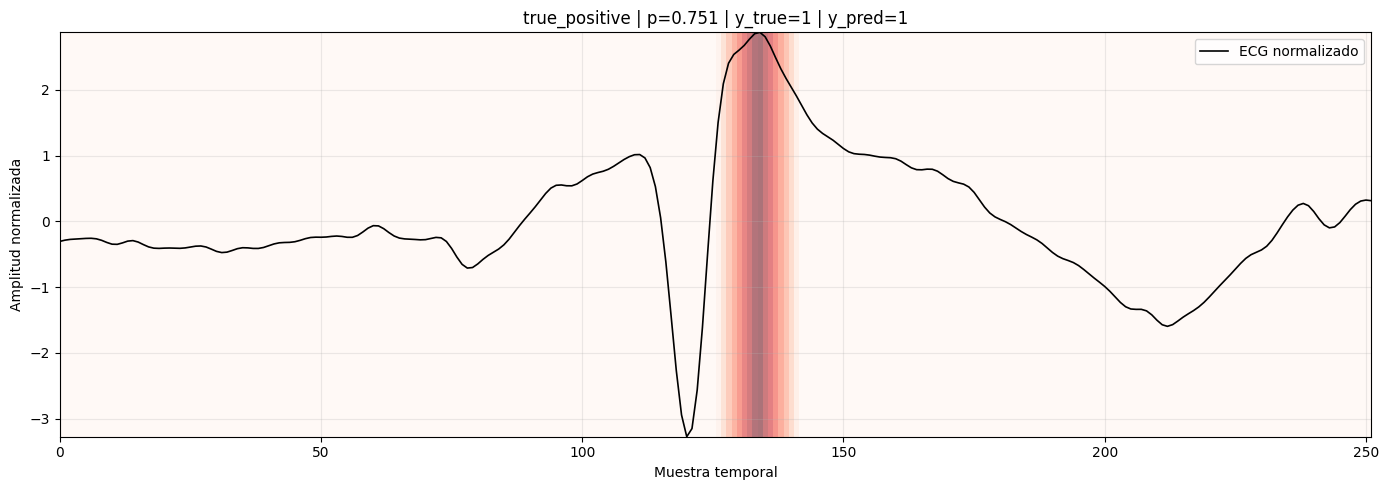

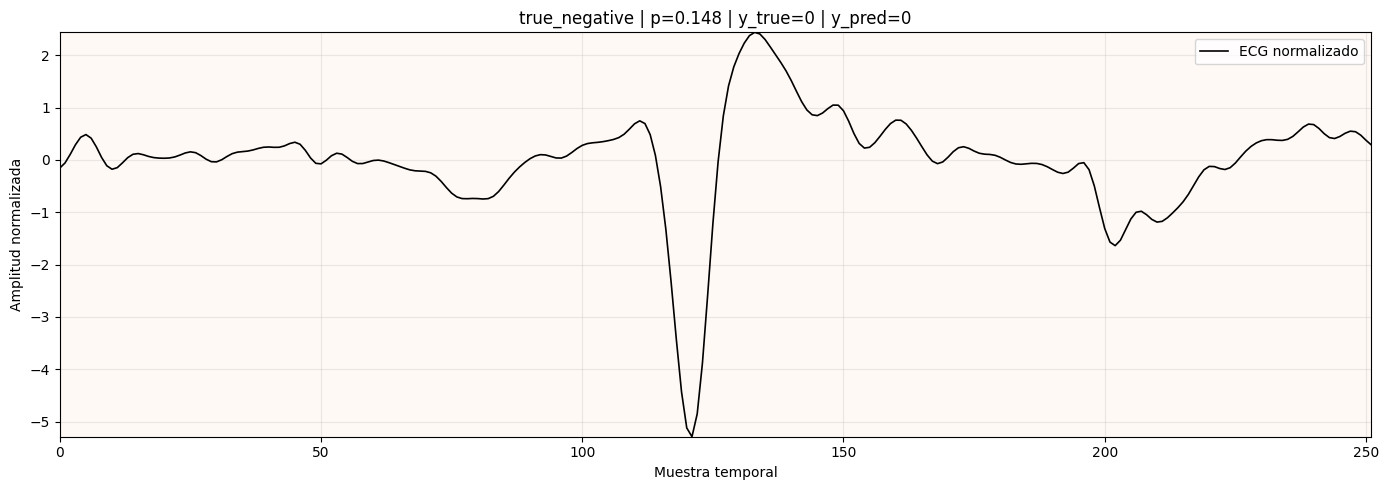

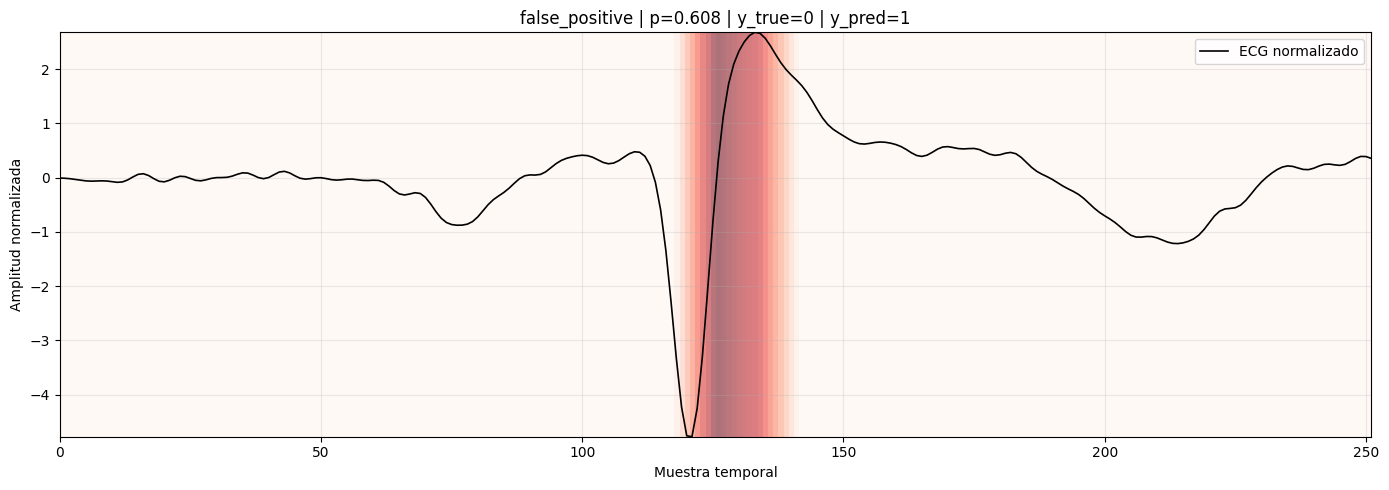

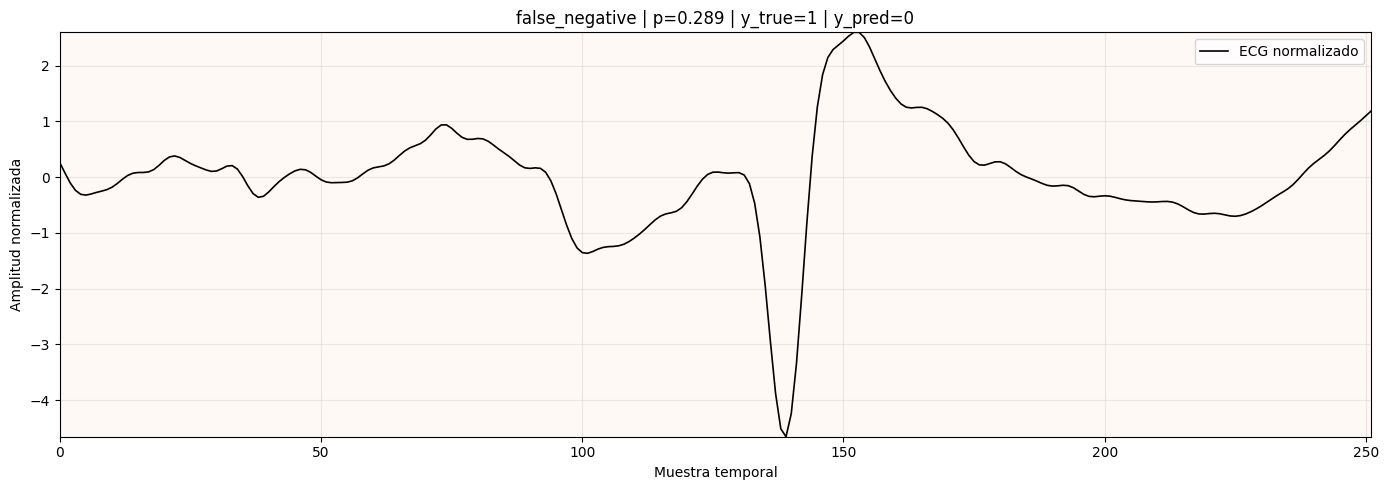

In [40]:
import matplotlib.pyplot as plt
from IPython.display import display
def plot_grad_cam_result(
    result,
    title,
):
    test_index = result[
        "test_index"
    ]

    signal = signals_test_tensor[
        test_index
    ].squeeze().numpy()

    cam = result["cam"]

    probability = result[
        "probability"
    ]

    y_true = result[
        "y_true"
    ]

    y_pred = result[
        "y_pred"
    ]

    time_axis = np.arange(
        len(signal)
    )

    fig, ax = plt.subplots(
        figsize=(14, 5)
    )

    ax.plot(
        time_axis,
        signal,
        color="black",
        linewidth=1.2,
        label="ECG normalizado",
    )

    # El mapa se muestra como intensidad de color.
    ax.imshow(
        cam[np.newaxis, :],
        aspect="auto",
        cmap="Reds",
        alpha=0.55,
        extent=[
            time_axis.min(),
            time_axis.max(),
            signal.min(),
            signal.max(),
        ],
    )

    ax.set_xlabel(
        "Muestra temporal"
    )

    ax.set_ylabel(
        "Amplitud normalizada"
    )

    ax.set_title(
        f"{title} | "
        f"p={probability:.3f} | "
        f"y_true={y_true} | "
        f"y_pred={y_pred}"
    )

    ax.legend()
    ax.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


for group_name, result in (
    grad_cam_results.items()
):
    plot_grad_cam_result(
        result=result,
        title=group_name,
    )

# 7.13. Interpretability with 1D Occlusion Analysis

Occlusion analysis masks successive temporal windows and measures how the positive-class logit changes. Positive importance means that masking the region decreases the positive prediction; negative importance means that masking it increases the positive prediction.


In [47]:
def occlusion_analysis_1d(
    model,
    signal,
    device,
    window_size=16,
    stride=4,
    baseline_value=0.0,
):
    """
    Compute temporal importance using occlusion analysis.

    Importance is defined as:

        logit_original - logit_ocluido

    Positive values indicate that the region supported
    the positive-class prediction.
    """

    model.eval()

    if signal.ndim == 2:
        signal = signal.unsqueeze(0)

    assert signal.ndim == 3
    assert signal.shape[1:] == (
        1,
        252,
    )

    signal = signal.to(
        device
    ).float()

    signal_length = signal.shape[-1]

    assert window_size <= signal_length

    # Original prediction.
    with torch.no_grad():
        original_logit = float(
            model(signal)[0].cpu()
        )

    starts = list(
        range(
            0,
            signal_length
            - window_size
            + 1,
            stride,
        )
    )

    # Ensure that the final region is also covered.
    last_start = (
        signal_length
        - window_size
    )

    if last_start not in starts:
        starts.append(last_start)

    importance_sum = torch.zeros(
        signal_length,
        dtype=torch.float32,
    )

    contribution_count = torch.zeros(
        signal_length,
        dtype=torch.float32,
    )

    window_results = []

    for start in starts:
        end = start + window_size

        occluded_signal = signal.clone()

        occluded_signal[
            :,
            :,
            start:end
        ] = baseline_value

        with torch.no_grad():
            occluded_logit = float(
                model(
                    occluded_signal
                )[0].cpu()
            )

        logit_change = (
            original_logit
            - occluded_logit
        )

        importance_sum[
            start:end
        ] += logit_change

        contribution_count[
            start:end
        ] += 1

        window_results.append(
            {
                "start": start,
                "end": end,
                "occluded_logit": occluded_logit,
                "logit_change": logit_change,
            }
        )

    importance = (
        importance_sum
        / contribution_count.clamp_min(1.0)
    )

    original_probability = float(
        torch.sigmoid(
            torch.tensor(original_logit)
        )
    )

    assert torch.isfinite(
        importance
    ).all()

    assert torch.isfinite(
        torch.tensor(original_logit)
    )

    return {
        "original_logit": original_logit,
        "original_probability": original_probability,
        "importance": importance.numpy(),
        "window_results": window_results,
        "window_size": window_size,
        "stride": stride,
        "baseline_value": baseline_value,
    }

In [48]:
occlusion_results = {}

for group_name, result in (
    grad_cam_results.items()
):
    test_index = result[
        "test_index"
    ]

    signal = signals_test_tensor[
        test_index
    ]

    occlusion_results[group_name] = (
        occlusion_analysis_1d(
            model=final_model,
            signal=signal,
            device=device,
            window_size=16,
            stride=4,
            baseline_value=0.0,
        )
    )

    importance = (
        occlusion_results[
            group_name
        ]["importance"]
    )

    print(
        group_name,
        "| probabilidad original=",
        f"{occlusion_results[group_name]['original_probability']:.4f}",
        "| maximum importance=",
        f"{importance.max():.4f}",
        "| minimum importance=",
        f"{importance.min():.4f}",
    )

true_positive | probabilidad original= 0.7507 | maximum importance= 5.1367 | minimum importance= -0.6857
true_negative | probabilidad original= 0.1480 | maximum importance= 3.2430 | minimum importance= -0.5592
false_positive | probabilidad original= 0.6075 | maximum importance= 3.6265 | minimum importance= -0.0063
false_negative | probabilidad original= 0.2886 | maximum importance= 5.5001 | minimum importance= -0.7193


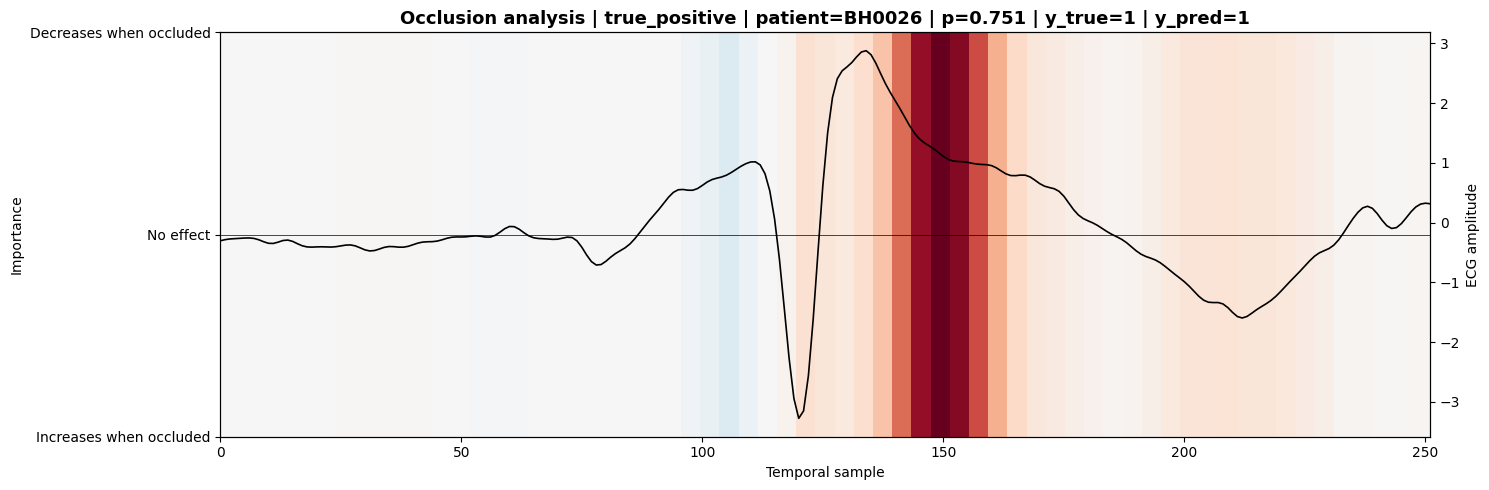

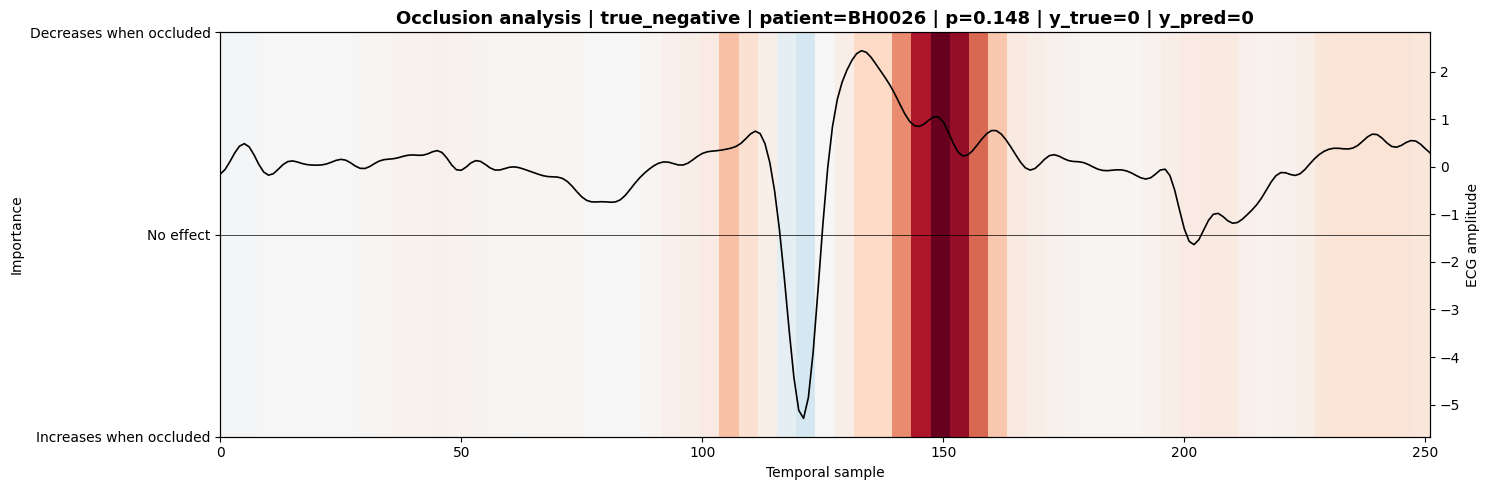

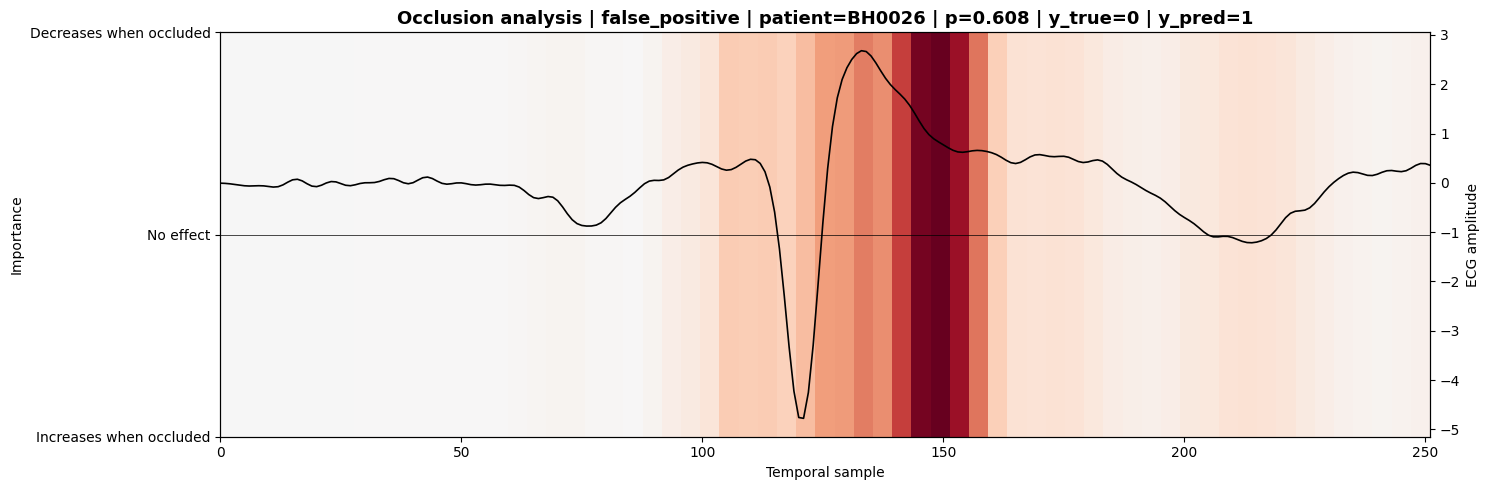

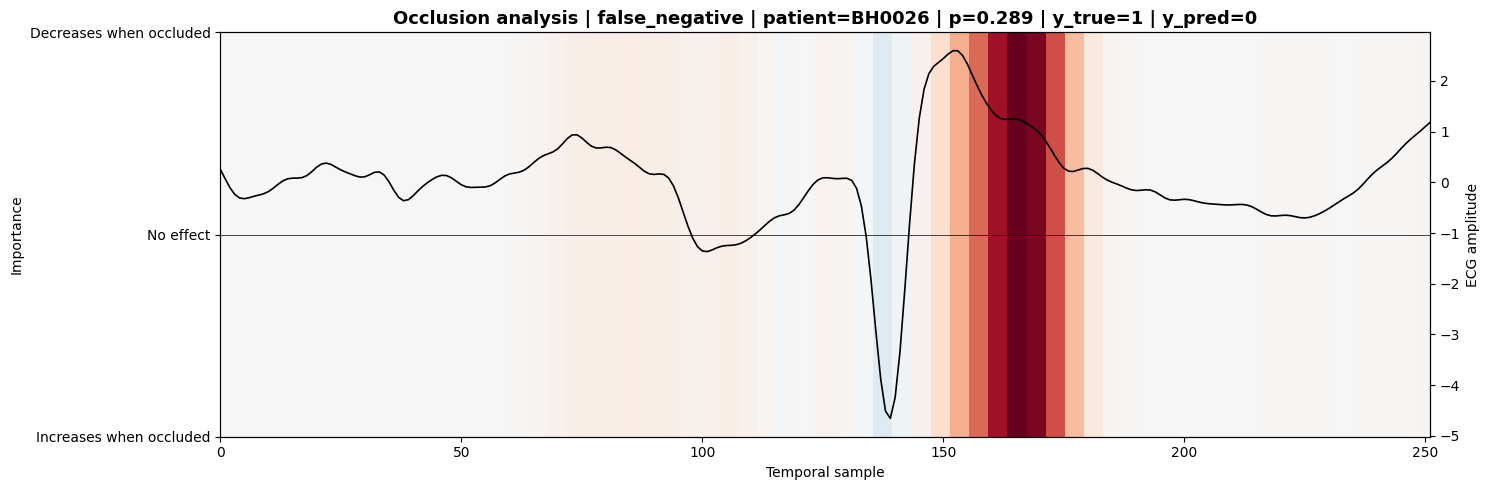

In [49]:
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

def plot_occlusion_result(
    result,
    occlusion_result,
    group_name,
):
    test_index = result[
        "test_index"
    ]

    signal = signals_test_tensor[
        test_index
    ].squeeze().numpy()

    importance = (
        occlusion_result[
            "importance"
        ]
    )

    probability = (
        occlusion_result[
            "original_probability"
        ]
    )

    y_true = result[
        "y_true"
    ]

    y_pred = result[
        "y_pred"
    ]

    patient_id = result[
        "patient_id"
    ]

    time_axis = np.arange(
        len(signal)
    )

    max_abs_importance = max(
        abs(importance.min()),
        abs(importance.max()),
        1e-8,
    )

    norm = TwoSlopeNorm(
        vmin=-max_abs_importance,
        vcenter=0.0,
        vmax=max_abs_importance,
    )

    fig, ax = plt.subplots(
        figsize=(15, 5),
    )

    ax.imshow(
        importance[np.newaxis, :],
        aspect="auto",
        cmap="RdBu_r",
        norm=norm,
        extent=[
            time_axis.min(),
            time_axis.max(),
            -1,
            1,
        ],
    )

    # Overlay the ECG signal on the occlusion heatmap.
    signal_axis = ax.twinx()
    signal_axis.plot(
        time_axis,
        signal,
        color="black",
        linewidth=1.2,
    )
    signal_axis.set_ylabel(
        "ECG amplitude",
        color="black",
    )
    signal_axis.tick_params(
        axis="y",
        labelcolor="black",
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.5,
    )

    ax.set_xlabel(
        "Temporal sample"
    )

    ax.set_ylabel(
        "Importance"
    )

    ax.set_yticks(
        [-1, 0, 1]
    )

    ax.set_yticklabels(
        [
            "Increases when occluded",
            "No effect",
            "Decreases when occluded",
        ]
    )

    ax.set_title(
        f"Occlusion analysis | "
        f"{group_name} | "
        f"patient={patient_id} | "
        f"p={probability:.3f} | "
        f"y_true={y_true} | "
        f"y_pred={y_pred}",
        fontsize=13,
        fontweight="bold",
    )

    fig.tight_layout()

    display(fig)

    plt.close(fig)

for group_name, result in (
    grad_cam_results.items()
):
    plot_occlusion_result(
        result=result,
        occlusion_result=occlusion_results[
            group_name
        ],
        group_name=group_name,
    )    

# 7.14. Apply Occlusion Analysis to All Test Signals

This section applies occlusion analysis to every test signal and summarizes importance maps by classification group. It is descriptive only: it does not retrain the model or alter test predictions.


In [50]:
all_test_occlusion_importance = []

test_size = len(
    signals_test_tensor
)

for test_index in range(
    test_size
):
    result = occlusion_analysis_1d(
        model=final_model,
        signal=signals_test_tensor[
            test_index
        ],
        device=device,
        window_size=16,
        stride=4,
        baseline_value=0.0,
    )

    all_test_occlusion_importance.append(
        result["importance"]
    )

    if (
        (test_index + 1) % 100 == 0
        or test_index == 0
        or test_index == test_size - 1
    ):
        print(
            f"Processed "
            f"{test_index + 1}/"
            f"{test_size} signals"
        )


all_test_occlusion_importance = np.asarray(
    all_test_occlusion_importance,
    dtype=np.float32,
)

assert all_test_occlusion_importance.shape == (
    test_size,
    252,
)

assert np.isfinite(
    all_test_occlusion_importance
).all()

print(
    "Final shape:",
    all_test_occlusion_importance.shape,
)

Processed 1/1218 signals
Processed 100/1218 signals
Processed 200/1218 signals
Processed 300/1218 signals
Processed 400/1218 signals
Processed 500/1218 signals
Processed 600/1218 signals
Processed 700/1218 signals
Processed 800/1218 signals
Processed 900/1218 signals
Processed 1000/1218 signals
Processed 1100/1218 signals
Processed 1200/1218 signals
Processed 1218/1218 signals
Final shape: (1218, 252)


In [51]:
# Create classification groups.

test_group_masks = {
    "true_positive": (
        (test_labels == 1)
        & (test_predictions == 1)
    ),

    "true_negative": (
        (test_labels == 0)
        & (test_predictions == 0)
    ),

    "false_positive": (
        (test_labels == 0)
        & (test_predictions == 1)
    ),

    "false_negative": (
        (test_labels == 1)
        & (test_predictions == 0)
    ),
}

# Official test-set group counts.
test_group_counts = {
    group_name: int(mask.sum())
    for group_name, mask
    in test_group_masks.items()
}


print(
    "Official counts by group:"
)

for group_name, count in (
    test_group_counts.items()
):
    print(
        f"{group_name}: {count}"
    )


# Each test signal must belong to exactly
# one of the four groups.
assert sum(
    test_group_counts.values()
) == len(test_labels)

assert np.all(
    sum(
        mask.astype(np.int64)
        for mask in test_group_masks.values()
    ) == 1
)

Official counts by group:
true_positive: 245
true_negative: 823
false_positive: 128
false_negative: 22


In [52]:
tn, fp, fn, tp = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1],
).ravel()


assert test_group_counts[
    "true_positive"
] == int(tp)

assert test_group_counts[
    "true_negative"
] == int(tn)

assert test_group_counts[
    "false_positive"
] == int(fp)

assert test_group_counts[
    "false_negative"
] == int(fn)


print(
    "Confusion matrix:"
)

print(
    [
        [int(tn), int(fp)],
        [int(fn), int(tp)],
    ]
)

Confusion matrix:
[[823, 128], [22, 245]]


In [53]:
# Compute mean and median importance maps.

group_occlusion_summary = {}

for group_name, mask in (
    test_group_masks.items()
):
    group_importance = (
        all_test_occlusion_importance[
            mask
        ]
    )

    if len(group_importance) == 0:
        print(
            f"{group_name}: no signals"
        )
        continue

    group_occlusion_summary[
        group_name
    ] = {
        "n_signals": int(
            len(group_importance)
        ),

        "mean_importance": (
            group_importance.mean(axis=0)
        ),

        "median_importance": (
            np.median(
                group_importance,
                axis=0,
            )
        ),

        "std_importance": (
            group_importance.std(axis=0)
        ),
    }

    print(
        f"{group_name}: "
        f"{len(group_importance)} signals | "
        f"mean maximum="
        f"{group_importance.mean(axis=0).max():.4f} | "
        f"mean minimum="
        f"{group_importance.mean(axis=0).min():.4f}"
    )

true_positive: 245 signals | mean maximum=4.5240 | mean minimum=-0.0085
true_negative: 823 signals | mean maximum=0.5848 | mean minimum=-0.7960
false_positive: 128 signals | mean maximum=2.3853 | mean minimum=-0.0335
false_negative: 22 signals | mean maximum=2.4330 | mean minimum=-0.0542


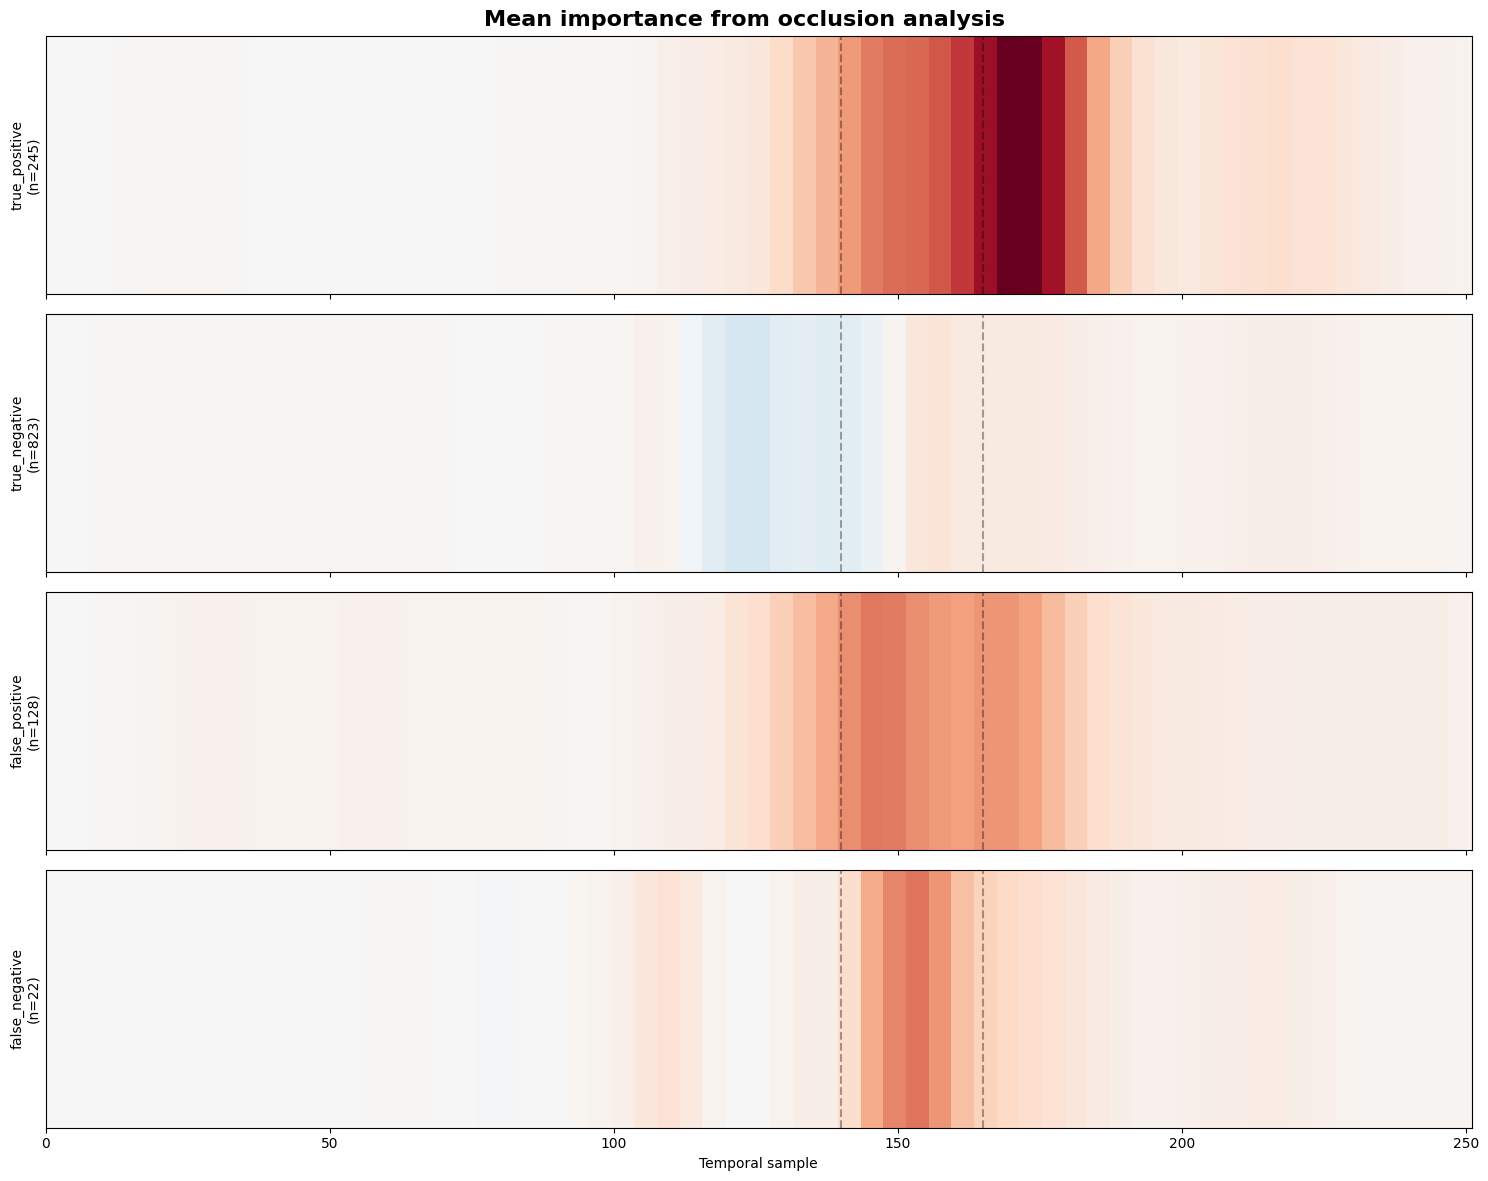

In [54]:
# Visualize mean importance maps.

available_groups = list(
    group_occlusion_summary.keys()
)

global_max = max(
    np.max(
        np.abs(
            group_occlusion_summary[
                group_name
            ]["mean_importance"]
        )
    )
    for group_name in available_groups
)

global_max = max(
    global_max,
    1e-8,
)


fig, axes = plt.subplots(
    len(available_groups),
    1,
    figsize=(15, 3 * len(available_groups)),
    sharex=True,
)

if len(available_groups) == 1:
    axes = [axes]


for ax, group_name in zip(
    axes,
    available_groups,
):
    summary = group_occlusion_summary[
        group_name
    ]

    mean_importance = summary[
        "mean_importance"
    ]

    ax.imshow(
        mean_importance[
            np.newaxis,
            :,
        ],
        aspect="auto",
        cmap="RdBu_r",
        vmin=-global_max,
        vmax=global_max,
        extent=[
            0,
            251,
            -1,
            1,
        ],
    )

    ax.set_ylabel(
        group_name
        + f"\n(n={summary['n_signals']})"
    )

    ax.set_yticks([])

    ax.axvline(
        140,
        color="black",
        linestyle="--",
        alpha=0.35,
    )

    ax.axvline(
        165,
        color="black",
        linestyle="--",
        alpha=0.35,
    )

axes[-1].set_xlabel(
    "Temporal sample"
)

fig.suptitle(
    "Mean importance from occlusion analysis",
    fontsize=16,
    fontweight="bold",
)

fig.tight_layout()

display(fig)

plt.close(fig)

In [55]:
normalized_group_summaries = {}

for group_name, mask in test_group_masks.items():
    group_importance = (
        all_test_occlusion_importance[mask]
    )

    if len(group_importance) == 0:
        continue

    max_abs_per_signal = np.max(
        np.abs(group_importance),
        axis=1,
        keepdims=True,
    )

    normalized_importance = (
        group_importance
        / np.maximum(
            max_abs_per_signal,
            1e-8,
        )
    )

    normalized_group_summaries[
        group_name
    ] = {
        "n_signals": len(group_importance),
        "mean_importance": normalized_importance.mean(
            axis=0
        ),
        "median_importance": np.median(
            normalized_importance,
            axis=0,
        ),
    }

    print(
        group_name,
        "n=",
        len(group_importance),
    )

true_positive n= 245
true_negative n= 823
false_positive n= 128
false_negative n= 22


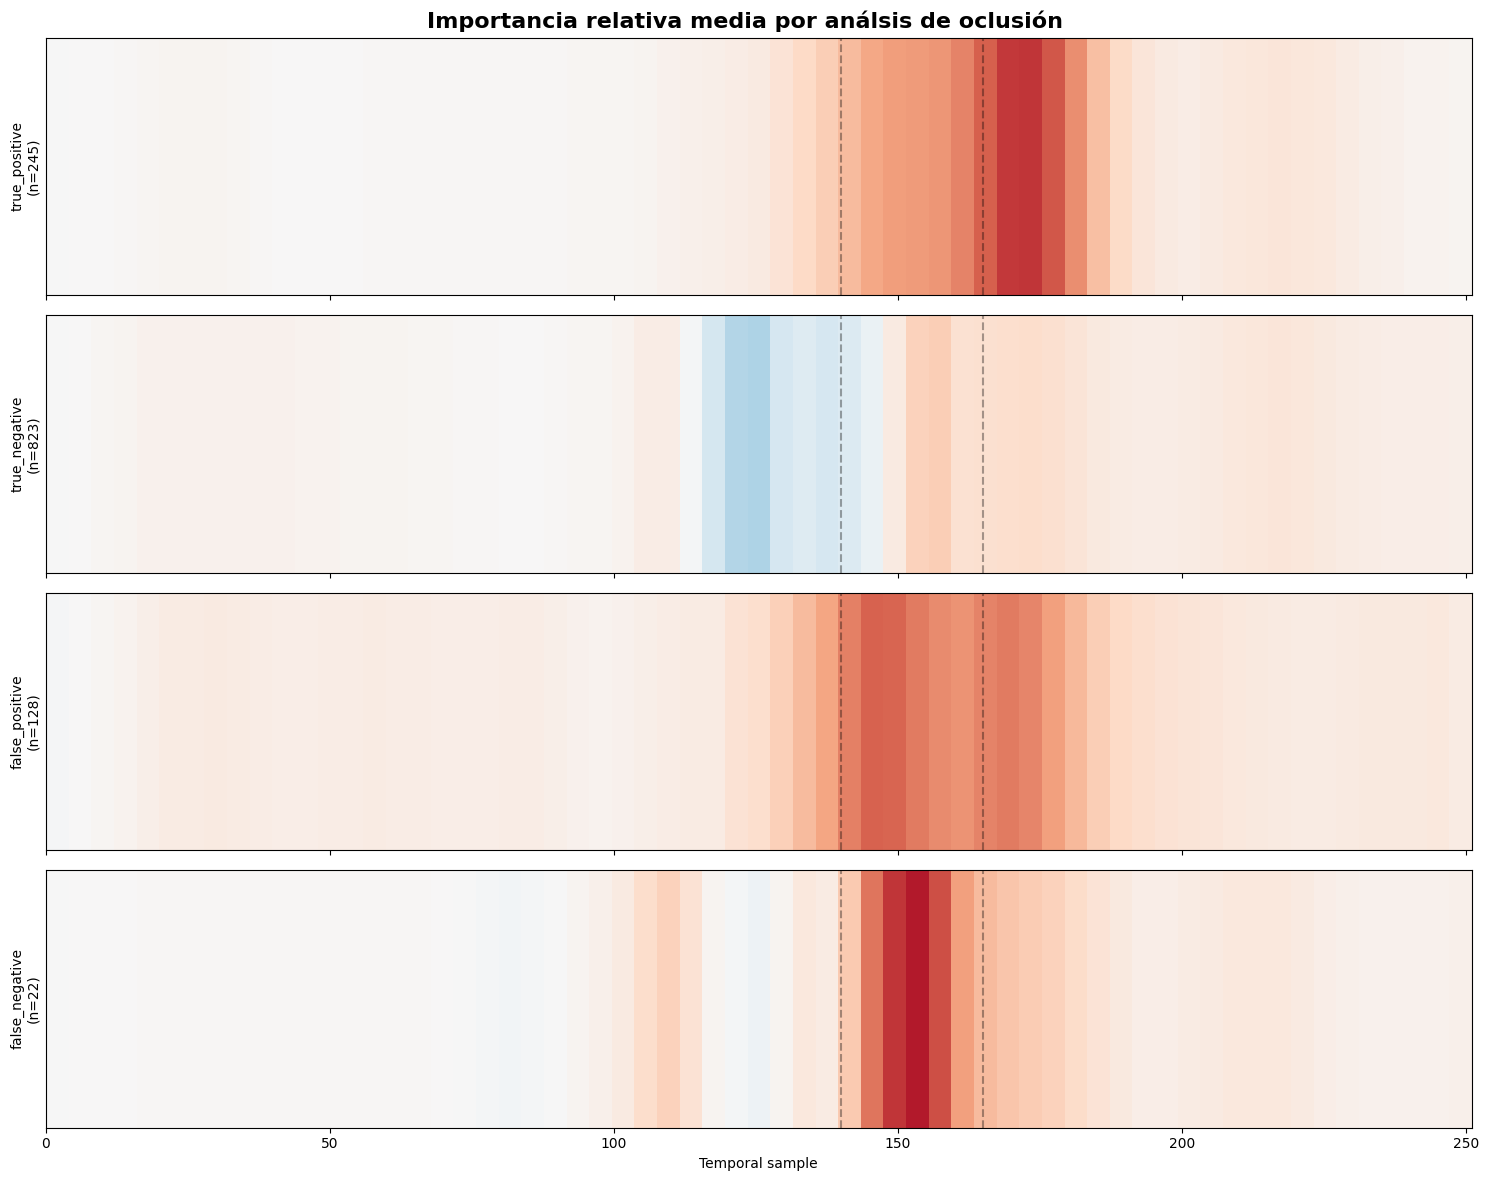

In [ ]:
available_groups = list(
    normalized_group_summaries.keys()
)

fig, axes = plt.subplots(
    len(available_groups),
    1,
    figsize=(15, 3 * len(available_groups)),
    sharex=True,
)

if len(available_groups) == 1:
    axes = [axes]


for ax, group_name in zip(
    axes,
    available_groups,
):
    mean_importance = (
        normalized_group_summaries[
            group_name
        ]["mean_importance"]
    )

    ax.imshow(
        mean_importance[np.newaxis, :],
        aspect="auto",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        extent=[
            0,
            251,
            -1,
            1,
        ],
    )

    ax.axvline(
        140,
        color="black",
        linestyle="--",
        alpha=0.35,
    )

    ax.axvline(
        165,
        color="black",
        linestyle="--",
        alpha=0.35,
    )

    ax.set_ylabel(
        group_name
        + f"\n(n={normalized_group_summaries[group_name]['n_signals']})"
    )

    ax.set_yticks([])

axes[-1].set_xlabel(
    "Temporal sample"
)

fig.suptitle(
    "Mean relative importance from occlusion analysis",
    fontsize=16,
    fontweight="bold",
)

fig.tight_layout()

display(fig)

plt.close(fig)

In [57]:
# Final classification masks.
test_group_masks = {
    "true_positive": (
        (test_labels == 1)
        & (test_predictions == 1)
    ),

    "false_positive": (
        (test_labels == 0)
        & (test_predictions == 1)
    ),

    "true_negative": (
        (test_labels == 0)
        & (test_predictions == 0)
    ),

    "false_negative": (
        (test_labels == 1)
        & (test_predictions == 0)
    ),
}


probability_rows = []

for group_name, mask in (
    test_group_masks.items()
):
    group_probabilities = (
        test_probabilities[mask]
    )

    probability_rows.append(
        {
            "classification_group": group_name,
            "n_signals": int(
                len(group_probabilities)
            ),
            "probability_min": float(
                group_probabilities.min()
            ),
            "probability_max": float(
                group_probabilities.max()
            ),
            "probability_mean": float(
                group_probabilities.mean()
            ),
            "probability_median": float(
                np.median(group_probabilities)
            ),
        }
    )


test_probability_by_group = pd.DataFrame(
    probability_rows
)


display(
    test_probability_by_group
)

,classification_group,n_signals,probability_min,probability_max,probability_mean,probability_median
0,true_positive,245,0.469435,0.993766,0.857945,0.899714
1,false_positive,128,0.405490,0.993259,0.668883,0.648885
2,true_negative,823,0.000020,0.399969,0.042887,0.006834
3,false_negative,22,0.001620,0.399136,0.180633,0.166849


In [58]:
probability_rows = []

for group_name, mask in (
    test_group_masks.items()
):
    group_probabilities = (
        test_probabilities[mask]
    )

    probability_rows.append(
        {
            "classification_group": group_name,
            "n_signals": int(
                len(group_probabilities)
            ),
            "probability_min": float(
                group_probabilities.min()
            ),
            "probability_p05": float(
                np.percentile(
                    group_probabilities,
                    5,
                )
            ),
            "probability_median": float(
                np.median(group_probabilities)
            ),
            "probability_p95": float(
                np.percentile(
                    group_probabilities,
                    95,
                )
            ),
            "probability_max": float(
                group_probabilities.max()
            ),
        }
    )


test_probability_by_group = pd.DataFrame(
    probability_rows
)

display(
    test_probability_by_group
)

,classification_group,n_signals,probability_min,probability_p05,probability_median,probability_p95,probability_max
0,true_positive,245,0.469435,0.601997,0.899714,0.981188,0.993766
1,false_positive,128,0.405490,0.427947,0.648885,0.965093,0.993259
2,true_negative,823,0.000020,0.000282,0.006834,0.258819,0.399969
3,false_negative,22,0.001620,0.006657,0.166849,0.367166,0.399136
